# 5.2 Comparación estadística y modelo de referencia

En esta sección evaluamos si las diferencias entre los tres modelos son estadísticamente significativas y relevantes en la práctica, identificamos el modelo de referencia (*baseline*) y calculamos la mejora mínima que debe demostrar un modelo más avanzado. Todas las pruebas fueron declaradas en el preregistro y los valores $p$ se reportan exactos.

In [12]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src.persist import is_done, load_pickle, save_pickle

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
print("Resultados:", C.RESULTS.name, "| modelos:", ", ".join(C.MODELS))

Resultados: results | modelos: CNN, MobileNetV2, ResNet-18


In [13]:
from src import stats as S

df = load_pickle(C.SUMMARY / "metricas_por_corrida.pkl")
w = S.wide(df)                       # semilla x modelo, F1 macro en prueba
R = len(w)
display(w.round(4))

model,CNN,MobileNetV2,ResNet-18
seed,,,
0,0.8428,0.7787,0.8815
1,0.8298,0.8045,0.8829
2,0.8257,0.8474,0.8690
3,0.8054,0.8187,0.8716
4,0.8455,0.8377,0.8794
5,0.7833,0.8146,0.8312
6,0.8413,0.7928,0.8567
7,0.8348,0.7815,0.8300


## Ranking

In [14]:
ranking = df.groupby("model")["f1_macro"].agg(media="mean", DE="std").sort_values("media", ascending=False)
ranking["posición"] = range(1, len(ranking) + 1)
ranking["rango medio (Friedman)"] = w.rank(axis=1, ascending=False).mean().loc[ranking.index]
display(ranking.round(4))

,media,DE,posición,rango medio (Friedman)
model,,,,
ResNet-18,0.8628,0.0216,1,1.125
CNN,0.8261,0.0215,2,2.250
MobileNetV2,0.8095,0.0250,3,2.625


## Supuestos

- **Independencia.** Cada semilla es una corrida independiente. Dentro de una semilla, los tres modelos comparten la partición y el orden de los datos, por lo que las observaciones están pareadas por semilla y se analizan como bloques.
- **Normalidad de las diferencias pareadas.** Es necesaria para la prueba t pareada y se evalúa con Shapiro-Wilk. Con pocas semillas la prueba tiene baja potencia, por lo que también reportamos la prueba de Wilcoxon, que no la requiere.

## Prueba global: Friedman

$H_0$: los tres modelos tienen la misma distribución de F1 macro. Dentro de cada semilla se ordenan los modelos de 1 a 3 y el estadístico compara las sumas de rangos $R_j$:

$$Q = \frac{12}{n k (k+1)} \sum_{j=1}^{k} R_j^2 - 3n(k+1),$$

con $n$ semillas y $k = 3$ modelos. El valor $p$ se obtiene de forma exacta, enumerando las $(3!)^n$ asignaciones de rangos posibles bajo $H_0$, o por Monte Carlo cuando son demasiadas. El tamaño de efecto es la W de Kendall, $W = Q / (n(k-1))$, entre 0 y 1. Con $k = 3$ y pocas semillas la prueba tiene baja potencia: un resultado no significativo no demuestra equivalencia.

In [15]:
fr = S.friedman_exact(w)
display(pd.Series({"Q": fr["Q"], "p exacto": fr["p_exacto"], "método": fr["metodo_p"], "p (aprox. χ²)": fr["p_chi2"],
                   "W de Kendall": fr["W_kendall"], "semillas": fr["n_bloques"]}, dtype=object).to_frame("valor"))

,valor
Q,9.75
p exacto,0.0048
método,exacto (1679616 permutaciones)
p (aprox. χ²),0.0076
W de Kendall,0.6094
semillas,8


## Comparaciones por pares

Para cada par $(A, B)$ y semilla $s$ calculamos $d_s = F1_{A,s} - F1_{B,s}$ y reportamos la diferencia media con su intervalo de confianza del 95 % (t y bootstrap pareado), la prueba t pareada con su tamaño de efecto $d_z = \bar d / s_d$, y la prueba de Wilcoxon de rangos con signo con la correlación rango-biserial $r = (W^+ - W^-)/(W^+ + W^-)$. Los valores $p$ se ajustan por Holm sobre las tres comparaciones. Una diferencia se considera relevante si $|\bar d| \ge \delta = 0.02$.

In [16]:
pw = S.pairwise(w)
cols = ["A", "B", "n", "dif_media", "ic_t_lo", "ic_t_hi", "ic_boot_lo", "ic_boot_hi", "d_z", "p_t", "p_t_holm",
        "W_wilcoxon", "p_wilcoxon", "p_wilcoxon_holm", "r_rango_biserial", "shapiro_p_dif", "supera_delta"]
display(pw[cols].round(4))
pw.to_csv(C.SUMMARY / "pruebas_pares.csv", index=False)
ph = S.posthoc(w)
if ph["disponible"]:
    print("Post-hoc de Nemenyi (p):")
    display(ph["nemenyi"].round(4))
    print("Post-hoc de Conover con Holm (p):")
    display(ph["conover"].round(4))

,A,B,n,dif_media,ic_t_lo,ic_t_hi,ic_boot_lo,ic_boot_hi,d_z,p_t,p_t_holm,W_wilcoxon,p_wilcoxon,p_wilcoxon_holm,r_rango_biserial,shapiro_p_dif,supera_delta
0,CNN,MobileNetV2,8,0.0166,-0.0141,0.0473,-0.0076,0.0404,0.4513,0.2425,0.2425,10.0,0.3125,0.3125,0.4444,0.4502,False
1,CNN,ResNet-18,8,-0.0367,-0.0554,-0.0180,-0.0503,-0.0214,-1.6435,0.0023,0.0047,1.0,0.0156,0.0312,-0.9444,0.7017,True
2,MobileNetV2,ResNet-18,8,-0.0533,-0.0771,-0.0295,-0.0722,-0.0355,-1.8690,0.0011,0.0034,0.0,0.0078,0.0234,-1.0000,0.8734,True


Post-hoc de Nemenyi (p):


model,CNN,MobileNetV2,ResNet-18
model,,,
CNN,NaN,NaN,NaN
MobileNetV2,NaN,NaN,NaN
ResNet-18,NaN,NaN,NaN


Post-hoc de Conover con Holm (p):


model,CNN,MobileNetV2,ResNet-18
model,,,
CNN,NaN,NaN,NaN
MobileNetV2,NaN,NaN,NaN
ResNet-18,NaN,NaN,NaN


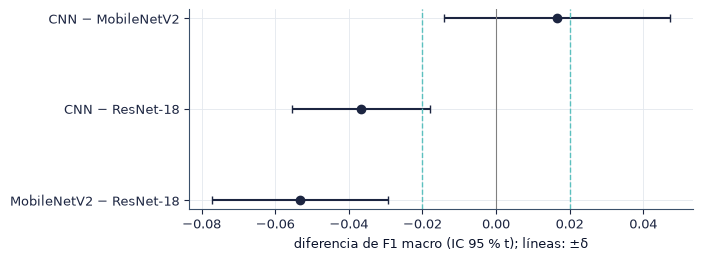

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
for i, r in pw.iterrows():
    ax.errorbar(r["dif_media"], i, xerr=[[r["dif_media"] - r["ic_t_lo"]], [r["ic_t_hi"] - r["dif_media"]]],
                fmt="o", color="#1C2541", capsize=3)
for x in (-C.DELTA, C.DELTA):
    ax.axvline(x, color="#5BC0BE", ls="--", lw=1)
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(range(len(pw)), [f"{a} − {b}" for a, b in zip(pw["A"], pw["B"])])
ax.set_xlabel("diferencia de F1 macro (IC 95 % t); líneas: ±δ")
ax.invert_yaxis()
P.save(fig, "5_2_diferencias_pareadas", pw)
plt.show()

## Prueba de McNemar por imagen

Para cada semilla y par de modelos contamos las imágenes de prueba que acierta solo $A$ ($b$) y las que acierta solo $B$ ($c$). $H_0$: $b$ y $c$ tienen la misma probabilidad. Usamos la versión exacta si $b + c < 25$ y, en otro caso, $\chi^2 = (|b-c|-1)^2/(b+c)$ con corrección de continuidad. Los valores $p$ se ajustan por Holm dentro de cada semilla. Esta prueba compara los modelos entrenados con una semilla concreta, no las arquitecturas en general.

In [18]:
seeds = list(w.index)
preds = {m: {s: load_pickle(C.run_dir(m, s) / "test_predictions.pkl") for s in seeds} for m in C.MODELS}
mc = S.mcnemar_all(preds)
mc.to_csv(C.SUMMARY / "mcnemar_por_semilla.csv", index=False)
med = load_pickle(C.SUMMARY / "semilla_mediana.pkl")
res_mc = mc.groupby(["A", "B"]).agg(semillas=("seed", "count"),
                                    significativas_holm=("p_holm_semilla", lambda p: int((p < C.ALPHA).sum())),
                                    b_medio=("b", "mean"), c_medio=("c", "mean")).reset_index()
res_mc["proporción significativa"] = res_mc["significativas_holm"] / res_mc["semillas"]
display(res_mc.round(3))
s_med = int(pd.Series(med).mode().iloc[0])
print(f"Semilla de referencia (la semilla mediana más frecuente entre modelos): {s_med}")
display(mc[mc["seed"] == s_med].round(4))

,A,B,semillas,significativas_holm,b_medio,c_medio,proporción significativa
0,CNN,MobileNetV2,8,1,34.500,26.875,0.125
1,CNN,ResNet-18,8,1,21.000,29.000,0.125
2,MobileNetV2,ResNet-18,8,4,15.125,30.750,0.500


Semilla de referencia (la semilla mediana más frecuente entre modelos): 1


,seed,A,B,b,c,exacto,estadistico,p,p_holm_semilla
3,1,CNN,MobileNetV2,34,23,False,1.7544,0.1853,0.3707
4,1,CNN,ResNet-18,20,29,False,1.3061,0.2531,0.3707
5,1,MobileNetV2,ResNet-18,14,34,False,7.5208,0.0061,0.0183


## AUC-ROC: bootstrap pareado

Para comparar el AUC-ROC macro (uno contra resto) usamos un bootstrap estratificado y pareado: remuestreamos las imágenes de prueba dentro de cada clase 10 000 veces y recalculamos la diferencia de AUC entre dos modelos sobre las mismas imágenes, con la semilla mediana de cada modelo. Elegimos este procedimiento en lugar de la prueba de DeLong porque no disponemos de una implementación verificada para el AUC macro multiclase.

In [19]:
import itertools

auc = []
for a, b in itertools.combinations(C.MODELS, 2):
    pa_, pb_ = preds[a][med[a]], preds[b][med[b]]
    assert np.array_equal(pa_["idx"], pb_["idx"])
    r = S.auc_bootstrap(pa_["y_true"], pa_["probs"], pb_["probs"])
    auc.append({"A": a, "B": b, "semilla A": med[a], "semilla B": med[b], **r})
auc = pd.DataFrame(auc)
display(auc.round(4))

,A,B,semilla A,semilla B,dif_auc,ic_lo,ic_hi,p_bootstrap,n_boot
0,CNN,MobileNetV2,1,5,0.0034,-0.0044,0.0114,0.3970,10000
1,CNN,ResNet-18,1,2,-0.0098,-0.0175,-0.0028,0.0062,10000
2,MobileNetV2,ResNet-18,5,2,-0.0132,-0.0219,-0.0053,0.0004,10000


## Modelo de referencia y umbral de mejora

El modelo de referencia es el de mayor F1 macro medio en prueba. Un modelo más avanzado debe compararse con él bajo el mismo protocolo (misma partición, $R$ semillas y pruebas pareadas). El umbral de mejora es el mayor valor entre $\delta$ y la diferencia mínima detectable con potencia de 0.80, $\text{MDE} = (z_{0.975}+z_{0.80})\,\hat\sigma_d/\sqrt{R}$, donde $\hat\sigma_d$ es la mayor desviación estándar de las diferencias pareadas observadas entre los modelos base.

In [20]:
mejor = ranking.index[0]
ci_b = S.mean_ci(w[mejor].to_numpy())
filas = []
for m in C.MODELS:
    if m == mejor:
        continue
    d = w[mejor] - w[m]
    filas.append({"frente a": m, "diferencia absoluta": d.mean(), "diferencia relativa (%)": 100 * d.mean() / w[m].mean()})
z = S.Z(1 - C.ALPHA / 2) + S.Z(C.POWER)
sd_d = pw["de_dif"].max()
mde = z * sd_d / np.sqrt(R)
umbral = max(C.DELTA, mde)
baseline = {"modelo": mejor, "media": ci_b["media"], "DE": ci_b["de"], "IC_t": ci_b["ic_t"], "IC_boot": ci_b["ic_boot"],
            "R": R, "sd_d": sd_d, "MDE": mde, "delta": C.DELTA, "umbral_mejora": umbral,
            "diferencias": pd.DataFrame(filas)}
display(pd.Series({"baseline": mejor, "F1 macro (media ± DE)": f"{ci_b['media']:.4f} ± {ci_b['de']:.4f}",
                   "IC 95 % t": f"[{ci_b['ic_t'][0]:.4f}, {ci_b['ic_t'][1]:.4f}]",
                   "IC 95 % bootstrap": f"[{ci_b['ic_boot'][0]:.4f}, {ci_b['ic_boot'][1]:.4f}]",
                   "MDE (potencia 0.80)": round(mde, 4), "δ": C.DELTA, "umbral de mejora": round(umbral, 4)},
                  dtype=object).to_frame("valor"))
display(baseline["diferencias"].round(4))

,valor
baseline,ResNet-18
F1 macro (media ± DE),0.8628 ± 0.0216
IC 95 % t,"[0.8448, 0.8808]"
IC 95 % bootstrap,"[0.8482, 0.8759]"
MDE (potencia 0.80),0.0364
δ,0.02
umbral de mejora,0.0364


,frente a,diferencia absoluta,diferencia relativa (%)
0,CNN,0.0367,4.4464
1,MobileNetV2,0.0533,6.5849


In [21]:
_ = save_pickle({"w": w, "ranking": ranking, "friedman": fr, "pares": pw,
             "posthoc": {k: v for k, v in ph.items() if k != "disponible"} if ph["disponible"] else {},
             "mcnemar": mc, "mcnemar_resumen": res_mc, "auc_bootstrap": auc, "baseline": baseline,
             "alpha": C.ALPHA, "delta": C.DELTA}, C.SUMMARY / "stats.pkl")

## Interpretación

In [22]:
def frase_par(r):
    sig = r["p_wilcoxon_holm"] < C.ALPHA or r["p_t_holm"] < C.ALPHA
    rel = abs(r["dif_media"]) >= C.DELTA
    base = (f"{r['A']} − {r['B']}: diferencia media {r['dif_media']:+.3f} (IC 95 % [{r['ic_t_lo']:.3f}, {r['ic_t_hi']:.3f}]), "
            f"t pareada p_Holm = {r['p_t_holm']:.4f}, Wilcoxon p_Holm = {r['p_wilcoxon_holm']:.4f}, d_z = {r['d_z']:.2f}.")
    if sig and rel:
        return base + " Es significativa y supera δ."
    if sig and not rel:
        return base + " Es significativa, pero menor que δ."
    if not sig and rel:
        return base + " Supera δ en promedio, pero no es significativa."
    return base + " No es significativa y es menor que δ."

costo = df.groupby("model")[["params", "ms_per_image"]].first()
txt = [f"**Global.** Friedman da Q = {fr['Q']:.3f}, p = {fr['p_exacto']:.4f} ({fr['metodo_p']}), W de Kendall = {fr['W_kendall']:.2f}. "
       + ("Se rechaza que los tres modelos tengan el mismo desempeño." if fr["p_exacto"] < C.ALPHA else
          "No se rechaza la igualdad global; con k = 3 y pocas semillas la prueba tiene baja potencia, por lo que el resultado no demuestra equivalencia.")]
txt += ["- " + frase_par(r) for _, r in pw.iterrows()]
mas_grande = costo["params"].idxmax()
txt.append(f"**Complejidad frente a desempeño.** {mas_grande} tiene más parámetros ({costo.loc[mas_grande, 'params'] / 1e6:.1f} M). "
           + ("Además es el de mayor F1 macro medio." if mas_grande == mejor else
              f"No es el de mayor F1 macro medio: con unas 1800 imágenes de entrenamiento y sin preentrenamiento, la mayor capacidad no se tradujo en mejor desempeño."))
acc_b = df[df["model"] == mejor]["accuracy"].mean()
txt.append(f"**Modelo de referencia.** {mejor}, con F1 macro {ci_b['media']:.3f} ± {ci_b['de']:.3f} y accuracy {acc_b:.3f}. "
           f"Un modelo más avanzado debe superarlo en al menos {umbral:.3f} de F1 macro, con significancia y bajo el mismo protocolo.")
txt.append(f"**Frente a la literatura.** La mediana de accuracy reportada en TrashNet es cercana a 96 % (Sección 3, §10), casi siempre con modelos "
           f"preentrenados en ImageNet, una sola corrida y particiones aleatorias que pueden repartir casi-duplicados. "
           f"Nuestro modelo de referencia se entrena desde cero, con partición agrupada y varias semillas. La diferencia de {0.96 - acc_b:.3f} "
           "frente a esa cifra combina el efecto del preentrenamiento con el del protocolo.")
display(Markdown("\n\n".join(txt)))

**Global.** Friedman da Q = 9.750, p = 0.0048 (exacto (1679616 permutaciones)), W de Kendall = 0.61. Se rechaza que los tres modelos tengan el mismo desempeño.

- CNN − MobileNetV2: diferencia media +0.017 (IC 95 % [-0.014, 0.047]), t pareada p_Holm = 0.2425, Wilcoxon p_Holm = 0.3125, d_z = 0.45. No es significativa y es menor que δ.

- CNN − ResNet-18: diferencia media -0.037 (IC 95 % [-0.055, -0.018]), t pareada p_Holm = 0.0047, Wilcoxon p_Holm = 0.0312, d_z = -1.64. Es significativa y supera δ.

- MobileNetV2 − ResNet-18: diferencia media -0.053 (IC 95 % [-0.077, -0.029]), t pareada p_Holm = 0.0034, Wilcoxon p_Holm = 0.0234, d_z = -1.87. Es significativa y supera δ.

**Complejidad frente a desempeño.** ResNet-18 tiene más parámetros (11.2 M). Además es el de mayor F1 macro medio.

**Modelo de referencia.** ResNet-18, con F1 macro 0.863 ± 0.022 y accuracy 0.871. Un modelo más avanzado debe superarlo en al menos 0.036 de F1 macro, con significancia y bajo el mismo protocolo.

**Frente a la literatura.** La mediana de accuracy reportada en TrashNet es cercana a 96 % (Sección 3, §10), casi siempre con modelos preentrenados en ImageNet, una sola corrida y particiones aleatorias que pueden repartir casi-duplicados. Nuestro modelo de referencia se entrena desde cero, con partición agrupada y varias semillas. La diferencia de 0.089 frente a esa cifra combina el efecto del preentrenamiento con el del protocolo.

## Conclusión

Comparamos los tres modelos con pruebas pareadas por semilla, valores $p$ exactos, intervalos de confianza y tamaños de efecto, distinguiendo la significancia estadística de la relevancia práctica. El modelo de referencia y su umbral de mejora quedan definidos para comparaciones posteriores.